In [1]:
import os, random, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda


## Q1

In [90]:
BATCH_SIZE=64

In [2]:
df_train = pd.read_csv("DLLAB_MIDSEM_14092026/DLLAB_MIDSEM_14092026/Q1/mnist_train.csv")
df_test = pd.read_csv("DLLAB_MIDSEM_14092026/DLLAB_MIDSEM_14092026/Q1/mnist_test.csv")
print(len(df_train), len(df_test))
df_train.head()

60000 10000


,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
df_train.iloc[0][1:].values.reshape(28, 28)

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [ ]:
class ImageDataset(torch.utils.data.Dataset):
    def __init__(self, df: pd.DataFrame):
        super().__init__()
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, index):
        img = self.df.iloc[index][1:].values.reshape(28, 28)
        label = self.df.iloc[index]["label"]
        # print(img.shape, label)
        img = torch.from_numpy(img)
        # print(img.shape, img.dtype)
        return img, label
    def display_image(self, idx):
        img, _ = self.__getitem__(idx)
        min_pixel = img.min().item()
        max_pixel = img.max().item()
        print(f"Min pixel val: {min_pixel}, Max pixel val: {max_pixel}")
        plt.imshow(img.numpy(), cmap="gray")
        plt.colorbar()
        plt.show()

Min pixel val: 0, Max pixel val: 255


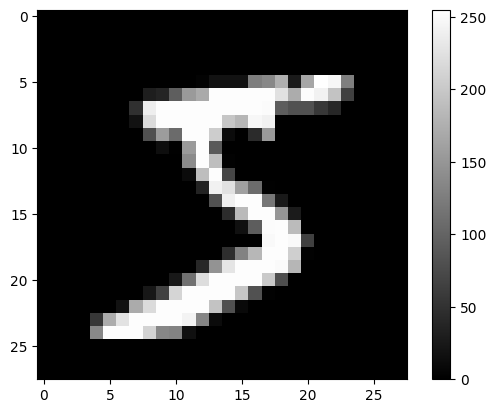

In [71]:
train_dataset = ImageDataset(df_train)
train_dataset.display_image(0)

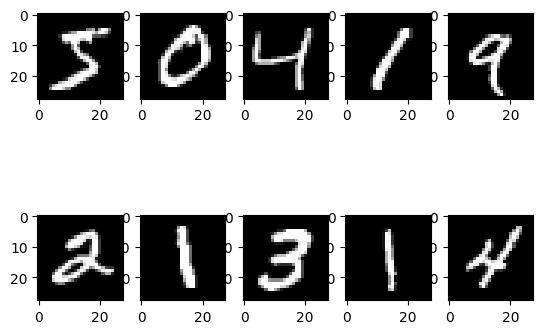

Labels: [5, 0, 4, 1, 9, 2, 1, 3, 1, 4]
Max pixel val: [255, 255, 255, 255, 255, 255, 255, 255, 255, 255]
Min pixel val: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [76]:
fig, axs = plt.subplots(2, 5)
labels = []
maxs = []
mins = []
for i in range(2):
    for j in range(5):
        img, label = train_dataset[i * 5 + j]
        maxs.append(img.max().item())
        mins.append(img.min().item())
        labels.append(label)
        axs[i, j].imshow(img.numpy(), cmap="gray")
plt.show()
print(f"Labels: {labels}")
print(f"Max pixel val: {maxs}")
print(f"Min pixel val: {mins}")

In [68]:
class QuantizedImageDataset(torch.utils.data.Dataset):
    def __init__(self, df:pd.DataFrame, K=4):
        super().__init__()
        self.df = df
        self.K = K
    def __len__(self):
        return len(self.df)
    def __getitem__(self, index):
        # (1, 28, 28)
        img = self.df.iloc[index][1:].values.reshape(28, 28)
        label = self.df.iloc[index]["label"]
        # print(img.dtype)
        img = np.clip(np.round(img * self.K / 256).astype(np.int64), 0, self.K -1, dtype=np.int64)
        # img = img.unsqueeze(0)
        img = torch.from_numpy(img)
        # print(img.shape, img.dtype)
        return img, label
    def display_image(self, idx):
        img, _ = self.__getitem__(idx)
        min_pixel = img.min().item()
        max_pixel = img.max().item()
        print(f"Min pixel val: {min_pixel}, Max pixel val: {max_pixel}")
        print(f"Unique: {torch.unique(img)}")
        plt.imshow(img.numpy(), cmap="gray")
        plt.colorbar()
        plt.show()


Min pixel val: 0, Max pixel val: 3
Unique: tensor([0, 1, 2, 3])


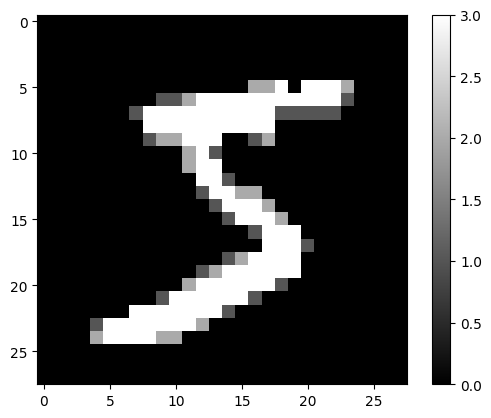

In [77]:
quantized_train = QuantizedImageDataset(df_train)
quantized_train.display_image(0)

Before quantization ------------------- After quantization


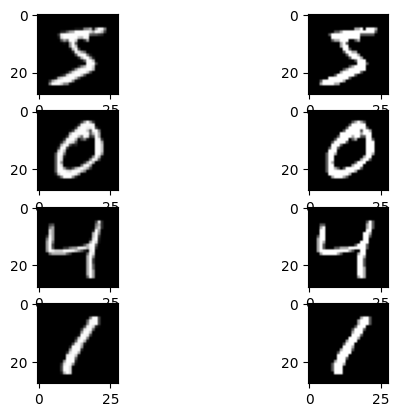

Unique values of quantized images: [tensor([0, 1, 2, 3]), tensor([0, 1, 2, 3]), tensor([0, 1, 2, 3]), tensor([0, 1, 2, 3]), tensor([0, 1, 2, 3]), tensor([0, 1, 2, 3]), tensor([0, 1, 2, 3]), tensor([0, 1, 2, 3])]


In [79]:
print("Before quantization ------------------- After quantization")
fig, axs = plt.subplots(4, 2)
unique_values = []
for i in range(4):
    for j in range(2):
        bimg, _ = train_dataset[i]
        aimg, _ = quantized_train[i]
        unique_values.append(torch.unique(aimg))
        axs[i][0].imshow(bimg, cmap="gray")
        axs[i][1].imshow(aimg, cmap="gray")
plt.show()
print(f"Unique values of quantized images: {unique_values}")

In [82]:
img, _ = quantized_train[0]
img.shape

torch.Size([28, 28])

In [83]:
img.dtype

torch.int64

In [125]:
def collate_fn(batch):
    # imgs, labels
    # print(type(batch))
    # print(len(batch))
    # print(batch)
    imgs, labels = zip(*batch)
    imgs = torch.stack(imgs)
    imgs = imgs / 3.0
    labels = torch.tensor(labels, dtype=torch.long)
    one_hot_labels = nn.functional.one_hot(labels, num_classes=10).float()
    return imgs, one_hot_labels

In [126]:
quantized_train = QuantizedImageDataset(df_train)
quantized_test = QuantizedImageDataset(df_test)
train_loader = torch.utils.data.DataLoader(quantized_train, batch_size=BATCH_SIZE, collate_fn=collate_fn, shuffle=True)
test_loader = torch.utils.data.DataLoader(quantized_test, batch_size=BATCH_SIZE, collate_fn=collate_fn, shuffle=False)

In [127]:
batch = next(iter(train_loader))
imgs, one_hot_labels = batch
print(imgs.shape)
print(one_hot_labels.shape)

torch.Size([64, 28, 28])
torch.Size([64, 10])


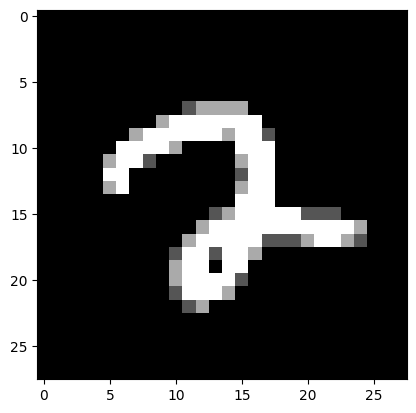

In [128]:
img = imgs[0]
plt.imshow(img, cmap="gray")
plt.show()

In [129]:
class MaskedConv2d(nn.Conv2d):
    def __init__(self, mask_type, *args, **kwargs):
        super().__init__(*args, **kwargs)
        if mask_type not in {'vertical', 'horizontal_a', 'horizontal_b'}:
            raise ValueError("mask type must be vertical, horizontal_a or horizontal_b")
        self.register_buffer("mask", torch.ones_like(self.weight))
        _, _, height, width = self.weight.shape
        center_h = height // 2
        center_w = width // 2
        self.mask[:, :, center_h + 1:, :] = 0
        if mask_type == "horizontal_a":
            self.mask[:, :, center_h, center_w:] = 0
        elif mask_type == "horizontal_b":
            self.mask[:, :, center_h, center_w+1:] = 0
        else: # vertical
            self.mask[:, :, center_h, :] = 0
    def forward(self, x):
        return nn.functional.conv2d(x, self.weight * self.mask, self.bias, self.stride, self.padding, self.dilation, self.groups)
